# Нобелевские лауреаты


## 1. Загрузка данных

Получаем список лауреатов по страницам API.

In [1]:
import requests

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates'
PAGE_SIZE = 100


def load_all_laureates(url=URL_LAUREATES, page_size=PAGE_SIZE):
    laureates = []
    offset = 0

    while True:
        response = requests.get(
            url,
            params={'limit': page_size, 'offset': offset},
            headers={
                'User-Agent': 'Mozilla/5.0',
                'Accept': 'application/json',
            },
            timeout=30,
        )
        response.raise_for_status()

        page = response.json()['laureates']
        laureates.extend(page)

        if len(page) < page_size:
            break

        offset += len(page)

    return laureates


raw_laureates = load_all_laureates()
print('Загружено записей:', len(raw_laureates))
print('Уникальных ID:', len({item['id'] for item in raw_laureates}))

Загружено записей: 1028
Уникальных ID: 1028


## 2. Обработка JSON

Приводим записи о людях и организациях к плоскому формату.

In [2]:
from json_dict_processing import (
    extract_nested_value,
    process_dictionary_with_config,
)
from laureates_configs import (
    CONFIG_PERSON,
    process_orgs,
    process_persons,
    process_year,
)


def get_laureate_data(laureate):
    if 'orgName' in laureate:
        result = process_orgs(laureate)
        result['type_'] = 'org'
    elif 'knownName' in laureate:
        result = process_persons(laureate)
        result['type_'] = 'person'
    else:
        raise ValueError(f"Неизвестный тип лауреата: {laureate.get('id')}")
    return result


laureates_data = [get_laureate_data(item) for item in raw_laureates]
print('Пример обработанной записи:')
example = laureates_data[0]
print({field: example[field] for field in ('id', 'name', 'type_')})
print('Количество наград:', len(example['prizes_relevant']))

Пример обработанной записи:
{'id': 745, 'name': 'A. Michael Spence', 'type_': 'person'}
Количество наград: 1


### Проверка обработки

Проверим извлечение вложенных полей и работу конфигураций.

In [3]:
sample = {
    'id': '745',
    'birth': {'date': '1943-05-06'},
    'knownName': {'en': 'A. Michael Spence'},
    'nobelPrizes': [{'awardYear': '2001', 'category': {'en': 'Economic Sciences'}}],
}
assert extract_nested_value(sample, ['birth', 'date']) == '1943-05-06'
assert extract_nested_value(sample, ['birth', 'unknown']) is None
assert process_year('1943-00-00') == 1943
assert process_year('0000-00-00') is None
assert process_dictionary_with_config(
    sample, {'year': (['birth', 'date'], process_year)}
) == {'year': 1943}
assert process_dictionary_with_config(sample, CONFIG_PERSON)['id'] == 745
assert process_persons(sample)['prizes_relevant'][0]['award_year'] == 2001
assert process_persons({'id': '8'})['prizes_relevant'] == []
assert process_orgs({'id': '9', 'orgName': {'en': 'Test org'}})['id'] == 9

assert len(laureates_data) == len(raw_laureates)
assert all(item['type_'] in ('person', 'org') for item in laureates_data)
assert all(isinstance(item['id'], int) for item in laureates_data)
assert all(isinstance(item['prizes_relevant'], list) for item in laureates_data)
print('Проверки обработчика пройдены')

Проверки обработчика пройдены


## 3. Первичный анализ (EDA)

Проверим полноту полей и распределение по типам лауреатов.

In [4]:
from collections import Counter
from dataset_helpers import group_by_attributes


def is_missing(value):
    return value is None or value == '' or value == []


def missing_by_field(records):
    fields = sorted({key for record in records for key in record})
    return {
        field: sum(is_missing(record.get(field)) for record in records)
        for field in fields
    }


missing_counts = missing_by_field(laureates_data)
print('Всего лауреатов:', len(laureates_data))
print('Количество пропусков по полям:', missing_counts)
print('Доли пропусков:')
for field, count in missing_counts.items():
    print(f'  {field}: {count / len(laureates_data):.1%}')

person_count = sum(item['type_'] == 'person' for item in laureates_data)
print(f'Люди: {person_count}; организации: {len(laureates_data) - person_count}')

for (laureate_type,), records in group_by_attributes(
    laureates_data, ['type_']
).items():
    print(f'Пропуски в типе {laureate_type} (всего {len(records)}):')
    for field, count in missing_by_field(records).items():
        if count:
            print(f'  {field}: {count} ({count / len(records):.1%})')

Всего лауреатов: 1028
Количество пропусков по полям: {'birth_year': 28, 'country_birth': 31, 'country_founded': 1004, 'country_now': 7, 'founded_year': 1001, 'gender': 28, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Доли пропусков:
  birth_year: 2.7%
  country_birth: 3.0%
  country_founded: 97.7%
  country_now: 0.7%
  founded_year: 97.4%
  gender: 2.7%
  id: 0.0%
  name: 0.0%
  prizes_relevant: 0.0%
  type_: 0.0%
Люди: 1000; организации: 28
Пропуски в типе person (всего 1000):
  country_birth: 3 (0.3%)
  country_now: 3 (0.3%)
Пропуски в типе org (всего 28):
  country_founded: 4 (14.3%)
  country_now: 4 (14.3%)
  founded_year: 1 (3.6%)


### Проверка ID

Проверим границы, повторы и разрывы в последовательности идентификаторов.

In [5]:
id_counts = Counter(record['id'] for record in laureates_data)
duplicate_ids = sorted(
    laureate_id for laureate_id, count in id_counts.items() if count > 1
)
ids_sorted = sorted(id_counts)
id_gaps = [
    (left_id, right_id)
    for left_id, right_id in zip(ids_sorted, ids_sorted[1:])
    if right_id - left_id > 1
]


def award_years(record):
    return sorted({
        prize['award_year'] for prize in record['prizes_relevant']
        if prize['award_year'] is not None
    })


for extreme_id in (ids_sorted[0], ids_sorted[-1]):
    record = next(item for item in laureates_data if item['id'] == extreme_id)
    print(f"ID {extreme_id}: {record['name']}, награды: {award_years(record)}")
print('Повторяющиеся ID:', duplicate_ids)
print('Количество пар ID с разрывом > 1:', len(id_gaps))
print('Первые 15 пар с разрывами:', id_gaps[:15])

ID 1: Wilhelm Conrad Röntgen, награды: [1901]
ID 1070: Michael Woodford, награды: [2026]
Повторяющиеся ID: []
Количество пар ID с разрывом > 1: 24
Первые 15 пар с разрывами: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633)]


### Переход к награждениям

Для анализа по категориям и годам развернем список премий в отдельные записи.

In [6]:
from attribute_manager import add_attribute
from dataset_helpers import (
    aggregate_groups,
    filter_records,
    group_by_attributes,
)
from aggregations import (
    count_records,
    max_metric,
    mean_metric,
    median_metric,
    top_n_records,
)


def as_award_rows(laureates):
    result = []
    for laureate in laureates:
        for prize in laureate['prizes_relevant']:
            if prize['award_year'] is None:
                continue
            result.append({
                'id': laureate['id'],
                'name': laureate['name'],
                'type_': laureate['type_'],
                'gender': laureate.get('gender'),
                'birth_year': laureate.get('birth_year'),
                'country': laureate.get('country_birth'),
                **prize,
            })
    return result


def distinct_by(records, fields):
    unique = []
    seen = set()
    for record in records:
        key = tuple(record[field] for field in fields)
        if key not in seen:
            seen.add(key)
            unique.append(record)
    return unique


def counts_by(records, fields):
    groups = group_by_attributes(records, fields)
    return aggregate_groups(groups, count_records)


award_rows = add_attribute(
    as_award_rows(laureates_data),
    'decade',
    lambda row: row['award_year'] // 10 * 10,
)
person_awards = filter_records(
    award_rows, lambda row: row['type_'] == 'person'
)
print('Записей о награждениях:', len(award_rows))
print('Награждений людей:', len(person_awards))
print('Категории:', sorted({row['category_en'] for row in award_rows
                            if row['category_en']}))

Записей о награждениях: 1036
Награждений людей: 1005
Категории: ['Chemistry', 'Economic Sciences', 'Literature', 'Peace', 'Physics', 'Physiology or Medicine']


## 4. Страны рождения

Сравниваем уникальных лауреатов по стране рождения, без учета повторных премий.

In [7]:
country_awards = filter_records(
    person_awards, lambda row: row['country'] is not None
)
all_country_people = distinct_by(country_awards, ['id'])
country_totals = counts_by(all_country_people, ['country'])
country_ranking = [
    {'country': country, 'laureates': count}
    for (country,), count in country_totals.items()
]
country_top5 = top_n_records(country_ranking, 'laureates', 5)
print('Топ-5 стран по уникальным лауреатам:')
for position, row in enumerate(country_top5, 1):
    print(f"  {position}. {row['country']}: {row['laureates']}")

# Один человек может встречаться в нескольких категориях
category_country = counts_by(
    distinct_by(country_awards, ['id', 'category_en']),
    ['category_en', 'country'],
)
print()
print('Топ-3 страны в каждой категории:')
for category in sorted({key[0] for key in category_country}):
    options = [
        {'country': country, 'laureates': count}
        for (category_name, country), count in category_country.items()
        if category_name == category
    ]
    print(category, [(row['country'], row['laureates'])
                     for row in top_n_records(options, 'laureates', 3)])

Топ-5 стран по уникальным лауреатам:
  1. USA: 299
  2. United Kingdom: 94
  3. Germany: 82
  4. France: 61
  5. Japan: 31

Топ-3 страны в каждой категории:
Chemistry [('USA', 59), ('United Kingdom', 26), ('Germany', 24)]
Economic Sciences [('USA', 56), ('United Kingdom', 7), ('Canada', 5)]
Literature [('France', 12), ('USA', 10), ('Sweden', 7)]
Peace [('USA', 19), ('France', 9), ('Germany', 6)]
Physics [('USA', 71), ('United Kingdom', 25), ('Germany', 24)]
Physiology or Medicine [('USA', 85), ('United Kingdom', 25), ('Germany', 22)]


### Динамика по десятилетиям

Для каждой страны считаем уникальных лауреатов внутри десятилетия награждения.

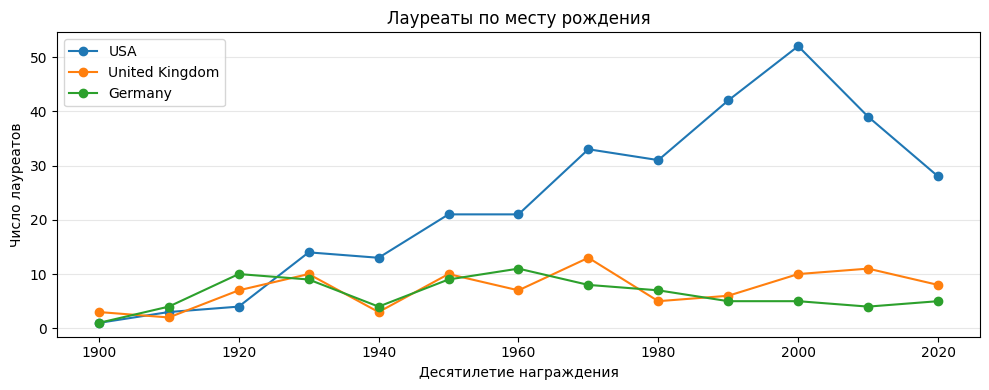

Лидеры каждого десятилетия:
  1900-е: France (9)
  1910-е: France (6)
  1920-е: Germany (10)
  1930-е: USA (14)
  1940-е: USA (13)
  1950-е: USA (21)
  1960-е: USA (21)
  1970-е: USA (33)
  1980-е: USA (31)
  1990-е: USA (42)
  2000-е: USA (52)
  2010-е: USA (39)
  2020-е: USA (28)


In [8]:
import matplotlib.pyplot as plt

country_decades = counts_by(
    distinct_by(country_awards, ['id', 'decade']),
    ['country', 'decade'],
)
selected_countries = [row['country'] for row in country_top5[:3]]
all_decades = sorted({row['decade'] for row in country_awards})

fig, ax = plt.subplots(figsize=(10, 4))
for country in selected_countries:
    series = [country_decades.get((country, decade), 0)
              for decade in all_decades]
    ax.plot(all_decades, series, marker='o', label=country)
ax.set(title='Лауреаты по месту рождения',
       xlabel='Десятилетие награждения', ylabel='Число лауреатов')
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print('Лидеры каждого десятилетия:')
for decade in all_decades:
    options = [
        {'country': country, 'laureates': count}
        for (country, dec), count in country_decades.items()
        if dec == decade
    ]
    leader = top_n_records(options, 'laureates', 1)[0]
    print(f"  {decade}-е: {leader['country']} ({leader['laureates']})")

## 5. Возраст при первой премии

Оцениваем возраст как разность годов награждения и рождения.

In [9]:
first_awards = []
for laureate in laureates_data:
    if laureate['type_'] != 'person' or laureate['birth_year'] is None:
        continue
    prizes = [prize for prize in laureate['prizes_relevant']
              if prize['award_year'] is not None]
    if not prizes:
        continue
    earliest = min(prizes, key=lambda prize: prize['award_year'])
    first_awards.append({
        'id': laureate['id'],
        'name': laureate['name'],
        'category_en': earliest['category_en'],
        'award_year': earliest['award_year'],
        'birth_year': laureate['birth_year'],
    })

first_awards = add_attribute(
    first_awards, 'age',
    lambda row: row['award_year'] - row['birth_year'],
)
first_awards = filter_records(
    first_awards, lambda row: 0 <= row['age'] <= 120
)
first_awards = add_attribute(
    first_awards, 'decade', lambda row: row['award_year'] // 10 * 10
)

age_mean = mean_metric(first_awards, 'age')
age_median = median_metric(first_awards, 'age')
print(f'Лауреатов с известным возрастом: {len(first_awards)}')
print(f'Средний возраст: {age_mean:.1f} года')
print(f'Медианный возраст: {age_median:.1f} года')
print('Максимальный возраст:', max_metric(first_awards, 'age'))
print('Пять самых старших при первом награждении:')
for row in top_n_records(first_awards, 'age', 5):
    print(f"  {row['name']}: {row['age']} ({row['award_year']})")

Лауреатов с известным возрастом: 1000
Средний возраст: 60.6 года
Медианный возраст: 61.0 года
Максимальный возраст: 97
Пять самых старших при первом награждении:
  John B. Goodenough: 97 (2019)
  Arthur Ashkin: 96 (2018)
  Henri B. Kagan: 96 (2026)
  John J. Hopfield: 91 (2024)
  Klaus Hasselmann: 90 (2021)


### Категории и десятилетия

Сравним среднее и медиану возраста. Категория определяется по первой премии.

Возраст при первой премии по категориям:
  Physics: среднее 57.8, медиана 56.0, n=230
  Physiology or Medicine: среднее 59.0, медиана 58.0, n=235
  Chemistry: среднее 59.4, медиана 58.0, n=199
  Peace: среднее 61.0, медиана 62.0, n=112
  Literature: среднее 65.0, медиана 67.0, n=123
  Economic Sciences: среднее 67.2, медиана 67.0, n=101


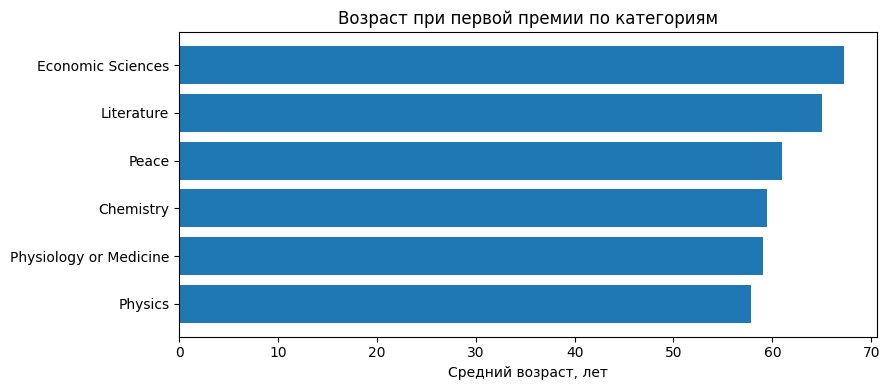

In [10]:
age_by_category = group_by_attributes(first_awards, ['category_en'])
age_categories = [
    {'category': category, 'mean': mean_metric(rows, 'age'),
     'median': median_metric(rows, 'age'), 'count': len(rows)}
    for (category,), rows in age_by_category.items()
]
age_categories.sort(key=lambda row: row['mean'])

print('Возраст при первой премии по категориям:')
for row in age_categories:
    print(f"  {row['category']}: среднее {row['mean']:.1f}, "
          f"медиана {row['median']:.1f}, n={row['count']}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([row['category'] for row in age_categories],
        [row['mean'] for row in age_categories])
ax.set(xlabel='Средний возраст, лет',
       title='Возраст при первой премии по категориям')
plt.tight_layout()
plt.show()

### Динамика возраста

Посмотрим изменение среднего возраста по десятилетиям.

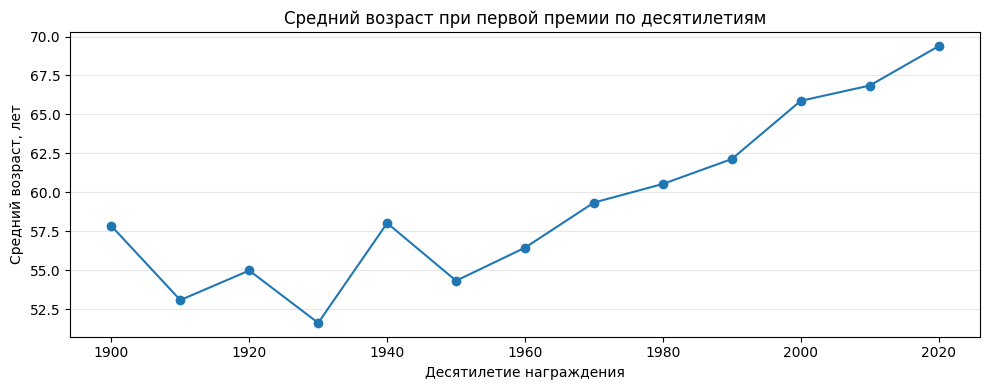

Последние пять десятилетий (средний возраст, n):
  1980-е: 60.5, n=93
  1990-е: 62.1, n=101
  2000-е: 65.9, n=119
  2010-е: 66.9, n=117
  2020-е: 69.4, n=81


In [11]:
age_by_decade = group_by_attributes(first_awards, ['decade'])
age_decades = sorted(
    (decade, mean_metric(rows, 'age'), len(rows))
    for (decade,), rows in age_by_decade.items()
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([item[0] for item in age_decades],
        [item[1] for item in age_decades], marker='o')
ax.set(title='Средний возраст при первой премии по десятилетиям',
       xlabel='Десятилетие награждения', ylabel='Средний возраст, лет')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Последние пять десятилетий (средний возраст, n):')
for decade, average, count in age_decades[-5:]:
    print(f'  {decade}-е: {average:.1f}, n={count}')

Средний возраст при первой премии в последние десятилетия вырос.

## 6. Женщины среди лауреатов

Считаем уникальных людей в целом, а для сравнения категорий и десятилетий -
уникальных людей внутри каждой категории или десятилетия.

In [12]:
gender_awards = filter_records(
    person_awards, lambda row: row['gender'] in ('male', 'female')
)
gender_people = distinct_by(gender_awards, ['id'])
women_people = filter_records(
    gender_people, lambda row: row['gender'] == 'female'
)
overall_women_share = len(women_people) / len(gender_people)
print('Лауреатов с известным полом:', len(gender_people))
print('Женщин:', len(women_people))
print(f'Доля женщин среди лауреатов: {overall_women_share:.1%}')

category_people = distinct_by(gender_awards, ['id', 'category_en'])
category_women = filter_records(
    category_people, lambda row: row['gender'] == 'female'
)
women_by_category = counts_by(category_women, ['category_en'])
all_by_category = counts_by(category_people, ['category_en'])
category_gender = []
for (category,), total in all_by_category.items():
    female = women_by_category.get((category,), 0)
    category_gender.append({
        'category': category, 'total': total, 'female': female,
        'female_share': female / total,
    })
category_gender.sort(key=lambda row: row['female'], reverse=True)
print('Всего по категориям:')
for row in category_gender:
    print(f"  {row['category']}: {row['female']} из {row['total']} "
          f"({row['female_share']:.1%})")

Лауреатов с известным полом: 1000
Женщин: 69
Доля женщин среди лауреатов: 6.9%
Всего по категориям:
  Peace: 21 из 113 (18.6%)
  Literature: 19 из 123 (15.4%)
  Physiology or Medicine: 14 из 235 (6.0%)
  Chemistry: 8 из 200 (4.0%)
  Physics: 5 из 230 (2.2%)
  Economic Sciences: 3 из 101 (3.0%)


### Динамика по десятилетиям

Покажем число лауреаток и их долю среди лауреатов с известным полом.

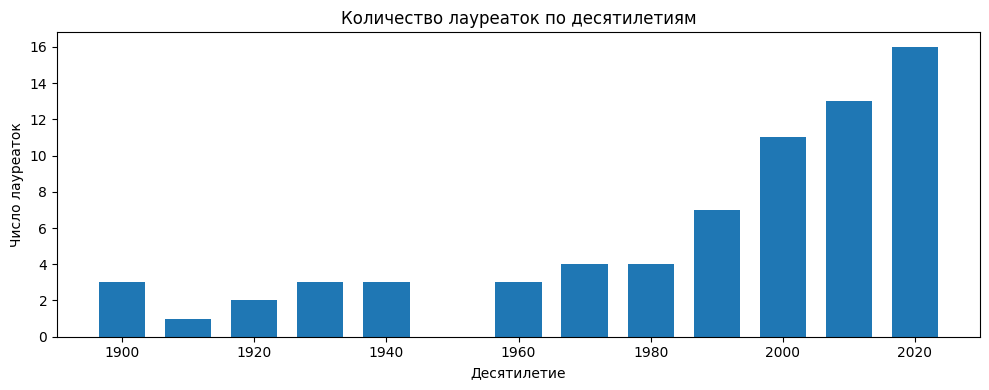

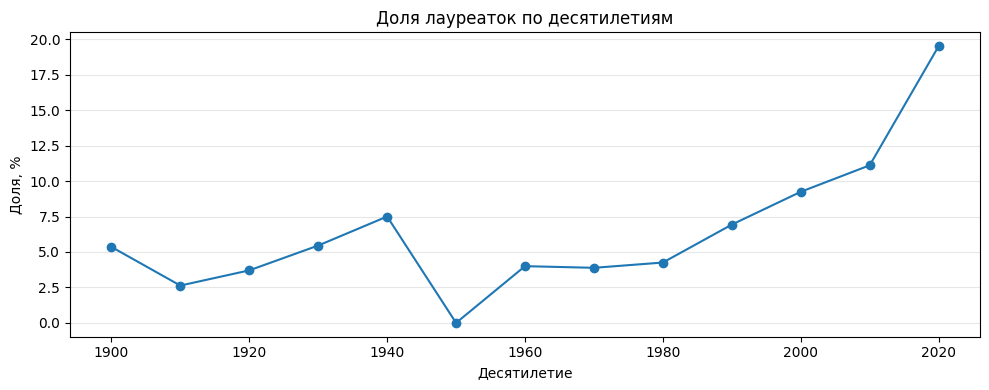

In [13]:
decade_people = distinct_by(gender_awards, ['id', 'decade'])
decade_women = filter_records(
    decade_people, lambda row: row['gender'] == 'female'
)
all_gender_decades = counts_by(decade_people, ['decade'])
women_decades = counts_by(decade_women, ['decade'])
decade_gender = [
    {'decade': decade, 'female': women_decades.get((decade,), 0),
     'total': total,
     'female_share': women_decades.get((decade,), 0) / total}
    for (decade,), total in sorted(all_gender_decades.items())
]

decades = [row['decade'] for row in decade_gender]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(decades, [row['female'] for row in decade_gender], width=7)
ax.set(title='Количество лауреаток по десятилетиям',
       xlabel='Десятилетие', ylabel='Число лауреаток')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(decades, [100 * row['female_share'] for row in decade_gender],
        marker='o')
ax.set(title='Доля лауреаток по десятилетиям',
       xlabel='Десятилетие', ylabel='Доля, %')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Последние два десятилетия

Доля лауреаток со временем растет. Сравним категории; 2020-е еще не завершились.

In [14]:
last_two_decades = set(decades[-2:])
recent_gender = distinct_by(
    filter_records(
        gender_awards, lambda row: row['decade'] in last_two_decades
    ),
    ['id', 'category_en', 'decade'],
)
recent_women = filter_records(
    recent_gender, lambda row: row['gender'] == 'female'
)
recent_totals = counts_by(recent_gender, ['category_en', 'decade'])
recent_female_counts = counts_by(recent_women, ['category_en', 'decade'])
print('Лауреатки по категориям и двум последним десятилетиям:')
for (category, decade), total in sorted(recent_totals.items()):
    female = recent_female_counts.get((category, decade), 0)
    print(f'  {decade}-е, {category}: {female}/{total} '
          f'({female / total:.1%})')

recent_by_category = counts_by(recent_women, ['category_en'])
if recent_by_category:
    recent_leader = max(recent_by_category, key=recent_by_category.get)
    print('Лидер по числу лауреаток за два десятилетия:',
          recent_leader[0], recent_by_category[recent_leader])

Лауреатки по категориям и двум последним десятилетиям:
  2010-е, Chemistry: 1/27 (3.7%)
  2020-е, Chemistry: 3/18 (16.7%)
  2010-е, Economic Sciences: 1/20 (5.0%)
  2020-е, Economic Sciences: 1/17 (5.9%)
  2010-е, Literature: 3/10 (30.0%)
  2020-е, Literature: 4/7 (57.1%)
  2010-е, Peace: 5/10 (50.0%)
  2020-е, Peace: 4/6 (66.7%)
  2010-е, Physics: 1/26 (3.8%)
  2020-е, Physics: 2/18 (11.1%)
  2010-е, Physiology or Medicine: 2/24 (8.3%)
  2020-е, Physiology or Medicine: 2/16 (12.5%)
Лидер по числу лауреаток за два десятилетия: Peace 9


## 7. Бонус: тексты мотиваций

Посчитаем частоту английских слов из поля `motivation.en`. У совместной премии текст мотивации может повторяться у нескольких лауреатов. В `stopwords.py` сохраним общеупотребительные служебные слова для удаления из частотного списка.

In [15]:
import re
from stopwords import STOPWORDS


def tokenize_motivation(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


motivation_rows = filter_records(
    award_rows, lambda row: bool(row.get('motivation_en'))
)
word_counts = Counter(
    word
    for row in motivation_rows
    for word in tokenize_motivation(row['motivation_en'])
)
print('Мотиваций с английским текстом:', len(motivation_rows))
print('Топ-50 слов до очистки:')
for position, (word, count) in enumerate(word_counts.most_common(50), 1):
    print(f'{position:2}. {word}: {count}')

common_english = [
    (word, count) for word, count in word_counts.most_common(50)
    if word in STOPWORDS
]
print('Частые служебные слова из топ-50:',
      ', '.join(word for word, _ in common_english))

Мотиваций с английским текстом: 1036
Топ-50 слов до очистки:
 1. of: 1291
 2. the: 1248
 3. for: 1149
 4. and: 670
 5. in: 449
 6. their: 394
 7. his: 376
 8. to: 278
 9. discovery: 211
10. discoveries: 172
11. a: 151
12. concerning: 124
13. development: 110
14. work: 106
15. on: 101
16. with: 99
17. which: 99
18. by: 82
19. theory: 74
20. contributions: 61
21. has: 60
22. structure: 58
23. that: 55
24. peace: 53
25. recognition: 48
26. economic: 45
27. human: 44
28. chemical: 43
29. as: 42
30. analysis: 42
31. new: 41
32. its: 39
33. synthesis: 38
34. pioneering: 38
35. an: 38
36. fundamental: 37
37. efforts: 36
38. between: 34
39. chemistry: 34
40. he: 34
41. her: 32
42. studies: 31
43. through: 31
44. international: 30
45. method: 30
46. especially: 29
47. methods: 29
48. having: 28
49. role: 27
50. research: 26
Частые служебные слова из топ-50: of, the, for, and, in, their, his, to, a, on, with, which, by, has, that, as, its, an, he, her, through


### Частые слова по категориям

После удаления stopwords сравним топ-10 слов по категориям и их пересечения.

Топ-25 после очистки:
 1. discovery: 211
 2. discoveries: 172
 3. concerning: 124
 4. development: 110
 5. work: 106
 6. theory: 74
 7. contributions: 61
 8. structure: 58
 9. peace: 53
10. recognition: 48
11. economic: 45
12. human: 44
13. chemical: 43
14. analysis: 42
15. new: 41
16. synthesis: 38
17. pioneering: 38
18. fundamental: 37
19. efforts: 36
20. between: 34
21. chemistry: 34
22. studies: 31
23. international: 30
24. method: 30
25. especially: 29
  Chemistry: ['chemical', 'chemistry', 'contributions', 'development', 'discovery', 'organic', 'structure', 'studies', 'synthesis', 'work']
  Economic Sciences: ['analysis', 'contributions', 'economic', 'empirical', 'financial', 'having', 'markets', 'pioneering', 'research', 'theory']
  Literature: ['art', 'great', 'human', 'i', 'life', 'narrative', 'poetic', 'poetry', 'power', 'recognition']
  Peace: ['between', 'efforts', 'human', 'international', 'peace', 'peaceful', 'rights', 'struggle', 'war', 'work']
  Physics: ['contributions

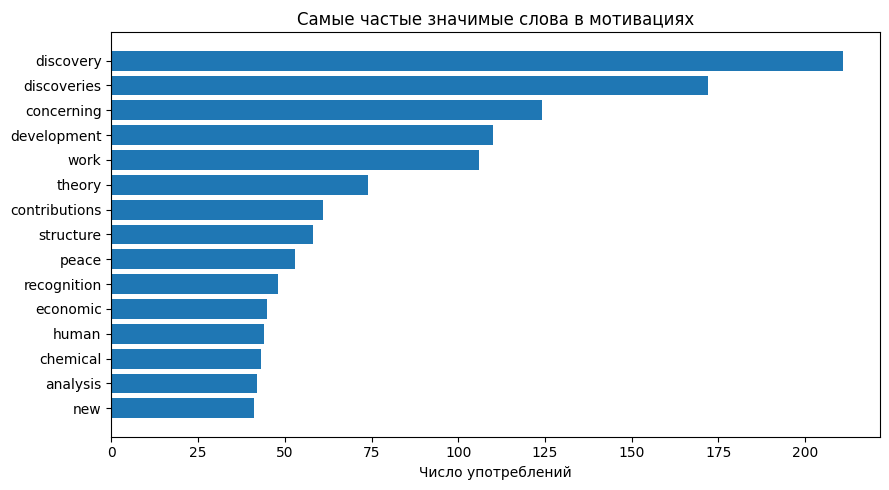

In [16]:
content_counts = Counter({
    word: count for word, count in word_counts.items()
    if word not in STOPWORDS
})
print('Топ-25 после очистки:')
for position, (word, count) in enumerate(content_counts.most_common(25), 1):
    print(f'{position:2}. {word}: {count}')

category_words = {}
for (category,), rows in group_by_attributes(
    motivation_rows, ['category_en']
).items():
    frequencies = Counter(
        word
        for row in rows
        for word in tokenize_motivation(row['motivation_en'])
        if word not in STOPWORDS
    )
    category_words[category] = {
        word for word, _ in frequencies.most_common(10)
    }

for category, words in sorted(category_words.items()):
    print(f'  {category}: {sorted(words)}')

categories = sorted(category_words)
print('Пересечения топ-10 между категориями:')
for index, category in enumerate(categories):
    for other in categories[index + 1:]:
        overlap = category_words[category] & category_words[other]
        print(f'  {category} / {other}: {len(overlap)}, '
              f'{sorted(overlap)}')

fig, ax = plt.subplots(figsize=(9, 5))
most_common_content = content_counts.most_common(15)
ax.barh([word for word, _ in reversed(most_common_content)],
        [count for _, count in reversed(most_common_content)])
ax.set(title='Самые частые значимые слова в мотивациях',
       xlabel='Число употреблений')
plt.tight_layout()
plt.show()

## 8. Выводы


In [17]:
from IPython.display import Markdown, display

country_leader = country_top5[0]
recent_women_leader = (
    recent_leader[0] if recent_by_category else 'нет данных'
)
summary = f"""
- Страны: лидирует {country_leader['country']} -
  {country_leader['laureates']} уникальных лауреатов
- Возраст первой премии: среднее {age_mean:.1f} года,
  медиана {age_median:.1f} года
- Гендерное распределение: доля женщин среди лауреатов составляет
  {overall_women_share:.1%}. Больше всего лауреаток за весь период -
  в категории {category_gender[0]['category']}, за последние два десятилетия -
  {recent_women_leader}
- Мотивации: после удаления служебных слов чаще всего встречается
  "{content_counts.most_common(1)[0][0]}"
"""
display(Markdown(summary))


- Страны: лидирует USA -
  299 уникальных лауреатов
- Возраст первой премии: среднее 60.6 года,
  медиана 61.0 года
- Гендерное распределение: доля женщин среди лауреатов составляет
  6.9%. Больше всего лауреаток за весь период -
  в категории Peace, за последние два десятилетия -
  Peace
- Мотивации: после удаления служебных слов чаще всего встречается
  "discovery"
